# **Notebook 4 – Activation Functions**

## **Q1. Sigmoid**

**Understand the Concept**

- Sigmoid converts the input into a value between 0 and 1.
- It is commonly used for binary classification.

**How It Works**

- Positive input gives an output closer to 1.
- Negative input gives an output closer to 0.
- Input near 0 gives an output near 0.5.

**Formula**

`σ(x) = 1 / (1 + e^(-x))`

**Range**

`0 < σ(x) < 1`

**Advantages**

- Simple to understand.
- Output is between 0 and 1.
- Useful for binary classification.

**Limitations**

- Can have vanishing gradient.
- Large positive or negative inputs make the gradient very small.
- Usually not preferred for hidden layers of deep networks.

**Vanishing Gradient**

- For very large or very small inputs, the sigmoid gradient becomes very small.
- This can make learning slow in deep networks.

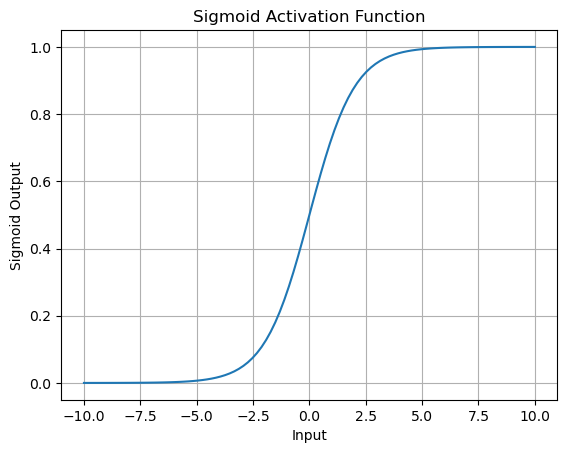

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.linspace(-10, 10, 100)
y = sigmoid(x)

plt.plot(x, y)
plt.xlabel("Input")
plt.ylabel("Sigmoid Output")
plt.title("Sigmoid Activation Function")
plt.grid()
plt.show()

## **Explanation**

- `sigmoid()` applies the sigmoid formula.
- The graph shows that the output stays between 0 and 1.
- At very large positive or negative inputs, the curve becomes almost flat, showing the vanishing-gradient problem.

## **Q2. Tanh**

**Understand the Concept**

- Tanh means hyperbolic tangent.
- Its output is centered around 0.

**How It Works**

- Negative inputs produce negative outputs.
- Input 0 gives output 0.
- Positive inputs produce positive outputs.

**Formula**

`tanh(x) = (e^x - e^(-x)) / (e^x + e^(-x))`

**Range**

`-1 < tanh(x) < 1`

**Advantages**

- Output is centered around 0.
- It gives both positive and negative values.
- It can work better than sigmoid in some hidden layers.

**Limitations**

- It can still suffer from vanishing gradients.
- Large inputs can make the gradient very small.
- ReLU is often preferred in deep networks.

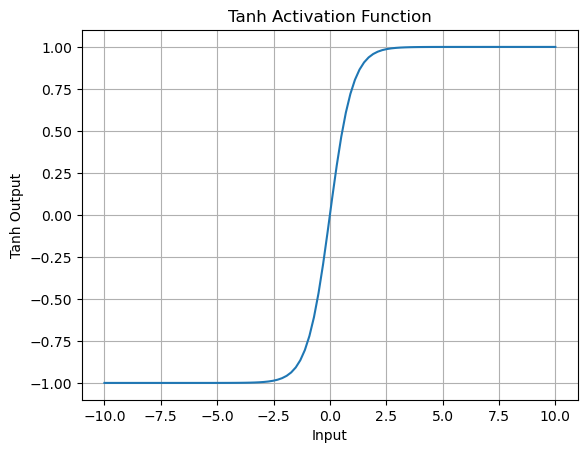

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def tanh(x):
    return np.tanh(x)

x = np.linspace(-10, 10, 100)
y = tanh(x)

plt.plot(x, y)
plt.xlabel("Input")
plt.ylabel("Tanh Output")
plt.title("Tanh Activation Function")
plt.grid()
plt.show()

## **Explanation**

- `np.tanh()` calculates Tanh.
- The output is between -1 and 1.
- The graph is centered around 0.
- Tanh can also have a vanishing-gradient problem for large inputs.

## **Q3. ReLU**

**Understand the Concept**

- ReLU means Rectified Linear Unit.
- It returns the input when the input is positive.
- It returns 0 when the input is negative.
- It is widely used in hidden layers.

**Formula**

`ReLU(x) = max(0, x)`

**How It Works**

- Positive values pass through.
- Negative values become 0.
- It is simple and fast.

**Why ReLU Became Popular**

- Simple calculation.
- Fast to compute.
- Helps reduce vanishing-gradient problems for positive inputs.
- Works well in deep neural networks.

**Dying ReLU Problem**

- A neuron can keep producing 0 for negative inputs.
- Its gradient can become 0.
- The neuron may stop learning.

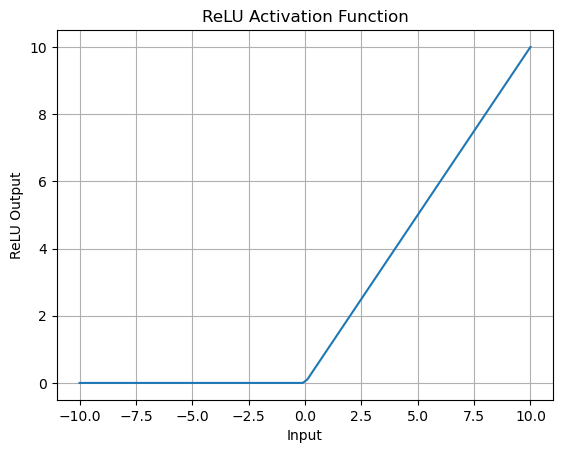

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def relu(x):
    return np.maximum(0, x)

x = np.linspace(-10, 10, 100)
y = relu(x)

plt.plot(x, y)
plt.xlabel("Input")
plt.ylabel("ReLU Output")
plt.title("ReLU Activation Function")
plt.grid()
plt.show()

## **Explanation**

- `np.maximum(0, x)` applies ReLU.
- Negative values become 0.
- Positive values stay unchanged.
- The graph shows the straight-line behavior for positive inputs.

## **Q4. Leaky ReLU**

**Understand the Concept**

- Leaky ReLU is a modified version of ReLU.
- It allows a small value for negative inputs.
- Its purpose is to reduce the dying ReLU problem.

**Difference from ReLU**

- ReLU: negative input → `0`
- Leaky ReLU: negative input → `αx`

**Formula**

`LeakyReLU(x) = x, if x > 0`

`LeakyReLU(x) = αx, if x <= 0`

Here, `α` is a small value such as `0.01`.

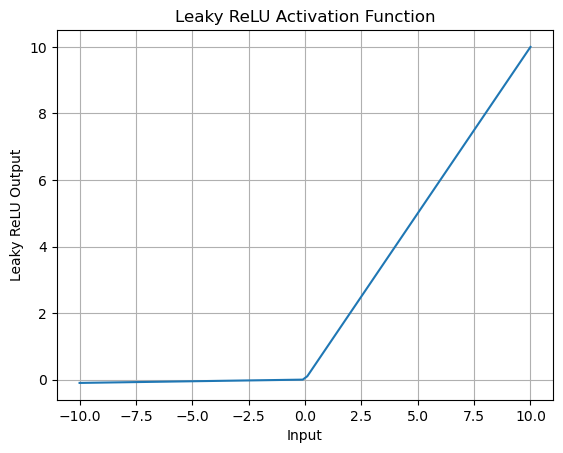

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def leaky_relu(x, alpha=0.01):
    return np.where(x > 0, x, alpha * x)

x = np.linspace(-10, 10, 100)
y = leaky_relu(x)

plt.plot(x, y)
plt.xlabel("Input")
plt.ylabel("Leaky ReLU Output")
plt.title("Leaky ReLU Activation Function")
plt.grid()
plt.show()

## **Explanation**

- Positive values pass through normally.
- Negative values are multiplied by `alpha`.
- A small negative output keeps a small gradient.
- This can reduce the dying ReLU problem.

## **Q5. Softmax**

**Understand the Concept**

- Softmax is mainly used for multiclass classification.
- It converts model scores into values that can be interpreted as probabilities.
- The probabilities of all classes add up to 1.

**Purpose**

- Used when there are more than two classes.
- Helps choose the class with the highest probability.

**Formula**

`softmax(xᵢ) = e^(xᵢ) / Σ e^(xⱼ)`

**Probability Interpretation**

- Each output is between 0 and 1.
- All class probabilities add up to 1.
- The class with the highest probability is usually selected.

**Multiclass Classification**

Example:

`[0.10, 0.75, 0.15]`

The predicted class is the second class because it has the highest probability.

In [5]:
import numpy as np

def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

scores = np.array([2.0, 5.0, 1.0])

probabilities = softmax(scores)

print("Class probabilities:")
print(probabilities)

print("Sum of probabilities:", probabilities.sum())
print("Predicted class:", np.argmax(probabilities))

Class probabilities:
[0.04661262 0.93623955 0.01714783]
Sum of probabilities: 1.0
Predicted class: 1


## **Explanation**

- `softmax()` converts class scores into probabilities.
- The probabilities add up to 1.
- `np.argmax()` returns the class with the highest probability.
- Subtracting the maximum score before `np.exp()` makes the calculation more numerically stable.

## **Q6. Compare the Activation Functions**

**Understand the Concept**

| Activation | Output Range | Common Use | Main Limitation |
|---|---|---|---|
| Sigmoid | 0 to 1 | Binary classification | Vanishing gradient |
| Tanh | -1 to 1 | Hidden layers in some networks | Vanishing gradient |
| ReLU | 0 to infinity | Hidden layers | Dying ReLU |
| Leaky ReLU | Small negative values to infinity | Hidden layers | Negative slope must be chosen |
| Softmax | 0 to 1, sum = 1 | Multiclass classification | Mainly used for class probabilities |

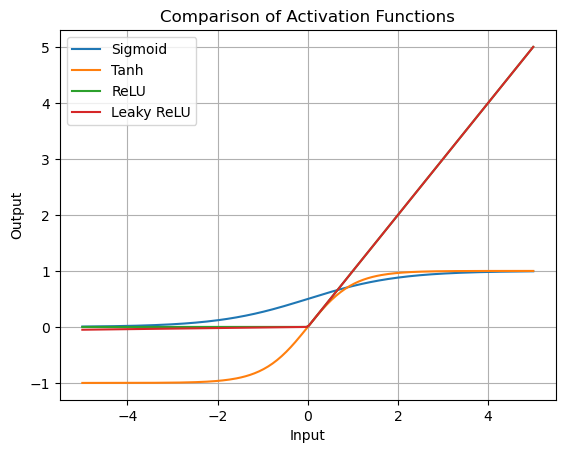

In [6]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 200)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)
leaky_relu = np.where(x > 0, x, 0.01 * x)

plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")
plt.plot(x, leaky_relu, label="Leaky ReLU")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Comparison of Activation Functions")
plt.legend()
plt.grid()
plt.show()

## **Explanation**

- The graph compares Sigmoid, Tanh, ReLU, and Leaky ReLU.
- Sigmoid stays between 0 and 1.
- Tanh stays between -1 and 1.
- ReLU makes negative values 0.
- Leaky ReLU keeps a small negative value.
- Softmax is not shown because it is normally applied to a group of class scores.

## **Q7. Why Do We Need Activation Functions?**

**Understand the Concept**

- Activation functions add non-linearity to a neural network.
- Without activation functions, a neural network would only perform linear transformations.
- Non-linearity allows the network to learn more complex patterns.

**How It Works**

- A layer first calculates a weighted sum.
- The activation function changes this result.
- The next layer can then learn more complex relationships.

**Why It Is Important**

- Real-world data is usually not purely linear.
- Neural networks need to learn complex patterns.
- Activation functions make deep neural networks useful for tasks such as image and classification problems.

**Without Activation Functions**

If every layer only performs:

`y = Wx + b`

then multiple linear layers can still be represented as one linear transformation.

So, adding more layers alone would not give the network the required non-linear learning ability.

In [7]:
import numpy as np

x = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])

# Linear transformation
linear_output = 2 * x + 1

# Apply ReLU activation
relu_output = np.maximum(0, linear_output)

print("Linear output:")
print(linear_output)

print("\nReLU output:")
print(relu_output)

Linear output:
[-3. -1.  1.  3.  5.]

ReLU output:
[0. 0. 1. 3. 5.]


## **Explanation**

- The first calculation is only a linear transformation.
- ReLU changes the output using a non-linear rule.
- This non-linearity helps neural networks learn complex patterns.
- That is why activation functions are an important part of neural networks.